# Using genomic-benchmarks-data

This tutorial demonstrates dataset discovery, metadata, loading, caching, and quality-control (QC) results with the full package. The full package exposes all published splits, including `test` data.

You will learn how to:

- discover collections, datasets, and the benchmark core set;
- inspect available filter values and metadata;
- load data and locate cached files; and
- explore QC results, summaries, and self-contained reports.

Install the package if it is not already available in this environment:

```python
%pip install genomic-benchmarks-data
```

In [1]:
from html import escape
from IPython.display import display
import pandas as pd
import genomic_benchmarks_data as gbd


def display_qc_report(path, height=900):
    """Display a standalone QC report without leaking its styles into Jupyter."""
    document = escape(path.read_text(encoding="utf-8"), quote=True)
    iframe = (
        f'<iframe srcdoc="{document}" '
        f'style="width: 100%; height: {height}px; border: 1px solid #ddd;"'
        '></iframe>'
    )
    display({"text/html": iframe}, raw=True)


## Discover datasets

In [2]:
collections = gbd.list_collections()
all_datasets = gbd.list_datasets()
binary_datasets = gbd.list_datasets(task_type="Binary classification")
core_datasets = gbd.list_datasets(core_set=True)

collection_summary = pd.DataFrame(
    [
        {
            "collection": collection,
            "DOI": doi,
            "datasets": len(all_datasets.get(collection, {})),
            "core datasets": len(core_datasets.get(collection, {})),
            "binary-classification datasets": len(
                binary_datasets.get(collection, {})
            ),
        }
        for collection, doi in collections.items()
    ]
).set_index("collection")
collection_summary


,DOI,datasets,core datasets,binary-classification datasets
collection,,,,
BEACON,https://doi.org/10.52202/079017-2949,3,1,0
GUE_v2,https://doi.org/10.48550/arXiv.2306.15006,32,2,32
OmniGenBench,https://doi.org/10.48550/arXiv.2505.14402,21,2,17
genomic-benchmarks,https://doi.org/10.1186/s12863-023-01123-8,7,1,7
mRNABench,https://doi.org/10.1101/2025.07.05.662870,11,2,0
miRBench,https://doi.org/10.1093/bioinformatics/btaf233,3,1,3
nucleotide_benchmarks,https://doi.org/10.1038/s41592-024-02523-z,16,0,16


### Select the core set

The core set is a selected subset of benchmarks. Pass `core_set=True` to select it, or `core_set=False` to select its complement. Core-set selection can be combined with the other dataset filters.

In [3]:
core_binary_datasets = gbd.list_datasets(
    core_set=True,
    task_type="Binary classification",
)

core_table = pd.DataFrame(
    [
        {
            "collection": collection,
            "dataset": dataset,
            "binary classification": dataset
            in core_binary_datasets.get(collection, {}),
            "description": description,
        }
        for collection, datasets in core_datasets.items()
        for dataset, description in datasets.items()
    ]
).sort_values(["collection", "dataset"], ignore_index=True)
core_table


,collection,dataset,binary classification,description
0,BEACON,CRISPROnTarget,False,Prediction of the knockout efficacy of single-...
1,GUE_v2,epigenetic_marks_prediction_H3K4me3,True,Prediction of epigenetic marks (H3K4me3 histon...
2,GUE_v2,transcription_factor_prediction_mouse_4,True,Prediction of transcription factor binding sit...
3,OmniGenBench,pro_seq_m_esculenta,True,Prediction of enhancer elements in Manihot esc...
4,OmniGenBench,promoter_strength_protoplast,False,Prediction of promoter strength in protoplasts...
5,genomic-benchmarks,drosophila_enhancers_stark,True,Prediction of enhancers
6,mRNABench,rnahl-human,False,Prediction of mRNA half-life from sequence. Ta...
7,mRNABench,translation-efficiency-human,False,Prediction of translation efficiency from sequ...
8,miRBench,AGO2_eCLIP_Manakov2022,True,Prediction of miRNA binding site


This tutorial uses the small core-set dataset `BEACON/CRISPROnTarget`, which provides `train`, `val`, and `test` splits. Change the two values in the next cell to explore another dataset.

In [4]:
COLLECTION = "BEACON"
DATASET = "CRISPROnTarget"

### Explore available filter values

These helpers show the exact metadata values that can be passed to `list_datasets()` for the selected collection.

In [5]:
filter_values = pd.DataFrame(
    [
        {
            "filter": "molecular_level",
            "available values": ", ".join(
                gbd.list_molecular_levels(COLLECTION)
            ),
        },
        {
            "filter": "task_category",
            "available values": ", ".join(
                gbd.list_task_categories(COLLECTION)
            ),
        },
        {
            "filter": "task_type",
            "available values": ", ".join(gbd.list_task_types(COLLECTION)),
        },
        {
            "filter": "species",
            "available values": ", ".join(gbd.list_species(COLLECTION)),
        },
    ]
).set_index("filter")
filter_values


,available values
filter,
molecular_level,"DNA, RNA"
task_category,"Engineering Prediction, RNA Processing Predict..."
task_type,Regression
species,Homo sapiens


## Inspect metadata

Use the targeted accessors for ordinary exploration. `load_metadata()` is also available when the complete packaged metadata is needed for bulk processing.

In [6]:
dataset_info = gbd.get_dataset_info(COLLECTION, DATASET)

dataset_summary = pd.Series(
    {
        "task type": dataset_info["task_type"],
        "core set": dataset_info["core_set"],
        "sequence columns": ", ".join(dataset_info["seq_col"]),
        "label columns": dataset_info["label_col"],
        "available splits": ", ".join(dataset_info["splits"]),
    },
    name="value",
).to_frame()

split_summary = pd.DataFrame(
    [
        {
            "split": split,
            "rows": gbd.get_split_info(COLLECTION, DATASET, split)[
                "dataset_size"
            ],
        }
        for split in dataset_info["splits"]
    ]
).set_index("split")

display(dataset_summary)
split_summary


,value
task type,Regression
core set,True
sequence columns,seq
label columns,label
available splits,"train, val, test"


,rows
split,
train,1453
val,207
test,416


## Load data

By default, `train` and `val` contain the sequence and label columns needed for the task.

In [7]:
train = gbd.load_dataset(COLLECTION, DATASET, "train")
validation = gbd.load_dataset(COLLECTION, DATASET, "val")

loaded_splits = pd.DataFrame(
    [
        {
            "split": "train",
            "rows": len(train),
            "default columns": ", ".join(train.columns),
        },
        {
            "split": "val",
            "rows": len(validation),
            "default columns": ", ".join(validation.columns),
        },
    ]
).set_index("split")
loaded_splits


,rows,default columns
split,,
train,1453,"seq, label"
val,207,"seq, label"


In [8]:
train.head()

,seq,label
0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,TTCATTTACTGACTTCAGATTGG,0.088202
2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


Use `columns="all"` to include identifiers and any other auxiliary columns. The preview makes the stable `id` and zero-based `row_index` visible.

In [9]:
train_all = gbd.load_dataset(
    COLLECTION, DATASET, "train", columns="all"
)
train_all.head()


,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:train:0000000,0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,BEACON:CRISPROnTarget:v1:train:0000001,1,TTCATTTACTGACTTCAGATTGG,0.088202
2,BEACON:CRISPROnTarget:v1:train:0000002,2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,BEACON:CRISPROnTarget:v1:train:0000003,3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,BEACON:CRISPROnTarget:v1:train:0000004,4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


The default `test` view starts with `id` and `row_index`, followed by the sequence and label columns. These identifiers make predictions traceable to examples.

In [10]:
test = gbd.load_dataset(COLLECTION, DATASET, "test")
test.head()

,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:test:0000000,0,GCAGACAAGAAGCGCAGGACAGG,0.208640
1,BEACON:CRISPROnTarget:v1:test:0000001,1,CCTTGCCTCCGCGAGCTCCGCGG,0.413518
2,BEACON:CRISPROnTarget:v1:test:0000002,2,ATCTGCCAGGCACTCAGCAATGG,0.313632
3,BEACON:CRISPROnTarget:v1:test:0000003,3,TTACGAGTTCACCTGTGTGAAGG,0.221238
4,BEACON:CRISPROnTarget:v1:test:0000004,4,CTGGCCCGTGTGAATGCCCTCGG,0.252790


## Locate a downloaded file

`download_dataset()` returns the complete cached file. The variable below contains its exact path; the saved output shows only portable file details.

In [11]:
cached_test_path = gbd.download_dataset(
    COLLECTION, DATASET, "test"
)

pd.Series(
    {
        "file exists": cached_test_path.is_file(),
        "filename": cached_test_path.name,
        "size (KiB)": round(cached_test_path.stat().st_size / 1024, 1),
    },
    name="value",
).to_frame()


,value
file exists,True
filename,CRISPROnTarget_test.csv.gz
size (KiB),9.2


## Explore QC results

Class QC examines individual splits. Split QC compares two splits for leakage. `load_qc_results()` returns parsed results; users who need the original combined CSV can instead call `download_qc_csv()`.

In [12]:
class_qc = gbd.load_qc_results("class")
split_qc = gbd.load_qc_results("split")

qc_metrics = pd.DataFrame(
    [
        {"QC type": qc_type, "check": check}
        for qc_type in ("class", "split")
        for check in gbd.list_qc_metrics(qc_type)
    ]
)
qc_metrics


,QC type,check
0,class,Duplicate Sequences between Labels
1,class,Per position nucleotide content
2,class,Per position reversed nucleotide content
3,class,Per sequence GC content
4,class,Per sequence dinucleotide content
5,class,Per sequence nucleotide content
6,class,Sequence Duplications within Labels
7,class,Sequence lengths
8,class,Unique bases
9,split,Data Leakage


### Inspect QC for the selected dataset

The first table shows the `train`-split class checks and any available scores. The second shows the relevant split-leakage comparison.

In [13]:
class_qc_table = (
    pd.DataFrame.from_dict(
        class_qc[COLLECTION][DATASET]["train"],
        orient="index",
    )
    .rename_axis("check")
    .reset_index()
)

split_leakage = pd.Series(
    split_qc[COLLECTION][DATASET]["comparisons"]["train"]["test"][
        "Data Leakage"
    ],
    name="value",
).to_frame()

display(class_qc_table)
split_leakage


,check,flag,accuracy,au_pr,au_roc
0,Unique bases,Pass,NaN,NaN,NaN
1,Sequence Duplications within Labels,Pass,NaN,NaN,NaN
2,Duplicate Sequences between Labels,Pass,NaN,NaN,NaN
3,Sequence lengths,Pass,0.500344,0.500344,0.500000
4,Per sequence GC content,Pass,0.537509,0.522658,0.544773
5,Per sequence nucleotide content,Warning,0.578114,0.566732,0.602088
6,Per sequence dinucleotide content,Pass,0.574673,0.561512,0.590402
7,Per position nucleotide content,Pass,0.578802,0.551402,0.578961
8,Per position reversed nucleotide content,Pass,0.578802,0.551402,0.578961


,value
flag,Pass
percentage_of_leaked_queries,0.00%
percentage_of_leaked_targets,0.00%


In [14]:
passing_class_qc = gbd.filter_datasets_by_qc(
    "class", flag="Pass"
)
passing_split_qc = gbd.filter_datasets_by_qc(
    "split", flag="Pass"
)

passing_summary = pd.DataFrame(
    [
        {
            "collection": collection,
            "passing class QC": len(passing_class_qc.get(collection, [])),
            "passing split QC": len(passing_split_qc.get(collection, [])),
        }
        for collection in collections
    ]
).set_index("collection")
passing_summary


,passing class QC,passing split QC
collection,,
BEACON,0,2
GUE_v2,7,5
OmniGenBench,0,7
genomic-benchmarks,1,0
mRNABench,0,3
miRBench,3,0
nucleotide_benchmarks,0,1


### Compare QC across collections

The class plot counts dataset–split–check results. The split plot counts detailed comparisons between available splits.

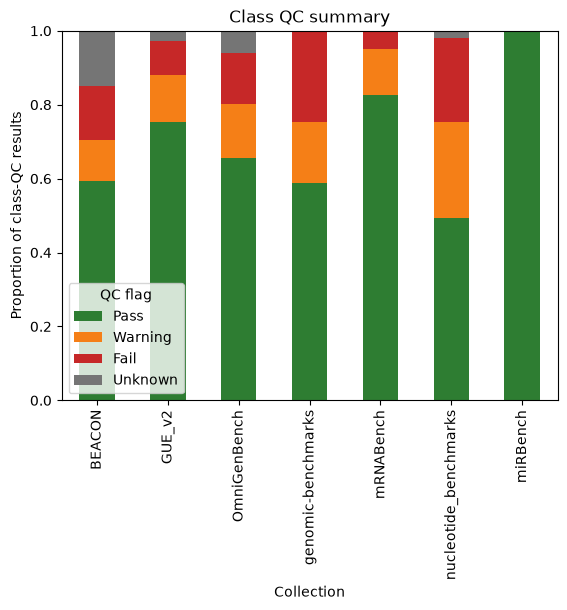

In [15]:
class_summary_plot = gbd.plot_qc_summary("class")


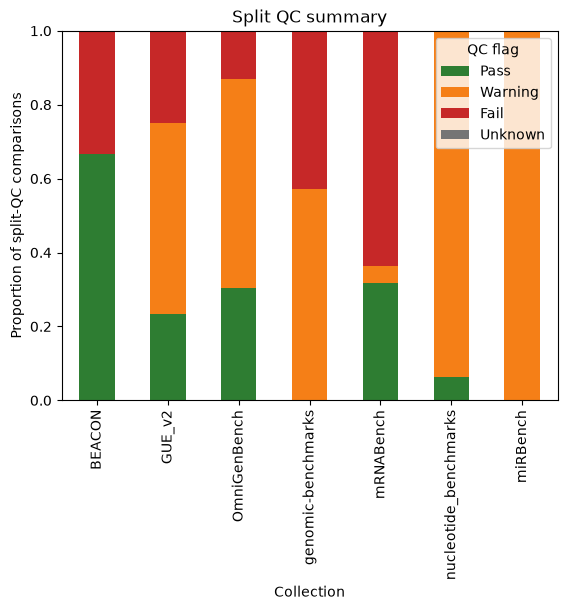

In [16]:
split_summary_plot = gbd.plot_qc_summary("split")


## Open self-contained QC reports

Run these cells locally to explore the interactive reports. Their large embedded HTML output is intentionally not stored in the repository notebooks.

<iframe srcdoc="<!DOCTYPE html>
<html lang="en">
<head>
 <meta charset="UTF-8">
 <meta name="viewport" content="width=device-width, initial-scale=1.0">
 <title>CRISPROnTarget_train.csv.gz: high vs low (seq) - gb-qc</title>
 <style>/* Make sure the root uses border-box sizing and doesn't allow the
 page to horizontally overflow. Individual <pre> blocks will
 still allow internal horizontal scrolling. */
html, body {
 box-sizing: border-box;
 overflow-x: hidden; /* prevent accidental page-wide horizontal scroll */
 margin: 0;
 padding: 0;
 background: #ffffff;
}
body {
 font-family: Arial, sans-serif;
 max-width: 100%; /* Prevents content from exceeding the viewport width */
}
.sidebar {
 width: 220px;
 background: #f4f4f4;
 padding: 15px;
 box-shadow: 2px 0 5px rgba(0, 0, 0, 0.1);
 height: 100vh; /* Full height */
 position: fixed; /* Fixed position */
 overflow-y: auto;
 z-index: 1000; /* Ensures it stays above other elements */
}
.sidebar a {
 display: inline-block;
 margin-left: 10px;
 text-decoration: none;
 color: #333;
 width: 175px;
}
.sidebar-item {
 display: flex;
 align-items: center;
 margin-bottom: 10px;
}
.status-icon {
 display: inline-flex;
 width: 40px;
 height: 40px;
 line-height: 40px;
 border-radius: 50%;
 color: white;
 font-size: 25px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
}
.status-icon-small {
 display: inline-flex;
 width: 28px;
 height: 28px;
 line-height: 28px;
 border-radius: 50%;
 color: white;
 font-size: 14px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
 margin: 0 4px 4px 0;
}
.status-pass { background-color: #2e7d32; color: #ffffff; }
.status-warn { background-color: #f57f17; color: #ffffff; }
.status-fail { background-color: #c62828; color: #ffffff; }
.status-unknown { background-color: #8a8983; color: #ffffff; }
.nucleotide-flags-container {
 display: flex;
 flex-wrap: wrap;
 gap: 10px;
 margin: -15px 0 15px 60px;
 align-items: flex-start;
}
.nucleotide-flag-item {
 display: flex;
 flex-direction: column;
 align-items: center;
 gap: 4px;
}
.nucleotide-flag-item .nucleotide-label {
 font-size: 14px;
 font-weight: bold;
 text-align: center;
 min-width: 24px;
}
.container {
 /* in some layouts the flex parent can grow to fit unbreakable children;
 make sure the container can shrink so .content's min-width:0 works */
 min-width: 0;
 box-sizing: border-box;
}
.content {
 margin-left: 260px;
 padding: 10px;
 padding-right: 8%;
 width: min(calc(100% - 260px), 1000px); /* Adjust width to avoid overlap */
 overflow-x: hidden;
 /* allow flex child to shrink below its content width so long lines
 inside (e.g. long sequences in <pre>) don't expand the whole page */
 min-width: 0;
 box-sizing: border-box;
}
#sequence-duplication-levels table {
 table-layout: fixed; /* Ensures columns respect defined widths */
 width: 100%;
 border-collapse: collapse;
}
#sequence-duplication-levels table th,
#sequence-duplication-levels table td {
 padding: 8px;
 border: 1px solid #ddd;
}
#sequence-duplication-levels table td {
 white-space: nowrap;
 overflow: hidden;
 text-overflow: ellipsis;
}
.count_column { width: 45px; }
.sequence_column { width: 95%; }
h1 { text-align: center; margin-bottom: 50px; }
section { margin-bottom: 50px; }
h2 { color: #333; border-bottom: 2px solid #ddd; padding-bottom: 5px; margin-left: 10px; }
h3 { color: #555; margin-bottom: 15px; }
.chart-container { margin-bottom: 30px; }
.data-item { font-size: 1.2em; margin-bottom: 10px; }
.data-item span { font-weight: bold; font-size: 1em; }

/* The key/value table a check leads with: the section's own table, addressed as
 a direct child so that a findings listing nested deeper inside the same
 section (see .qc-listing in report_design.css) keeps its own look. */
.table-section > table { width: 100%; border-collapse: collapse; margin: 20px 0; }
.table-section > table td { padding: 10px; border: 1px solid #ddd; text-align: center; }
.table-section > table td:first-child { text-align: left; width:
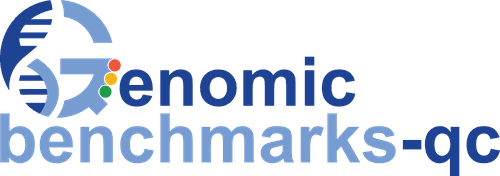

In [17]:
class_report = gbd.get_class_qc_report(
    COLLECTION, DATASET, split="train", seq_col="seq"
)
display_qc_report(class_report)

<iframe srcdoc="<!DOCTYPE html>
<html lang="en">
<head>
 <meta charset="UTF-8">
 <meta name="viewport" content="width=device-width, initial-scale=1.0">
 <title>CRISPROnTarget_test.csv.gz vs CRISPROnTarget_train.csv.gz: leakage - gb-qc</title>
 <style>
 /* Make sure the root uses border-box sizing and doesn't allow the
 page to horizontally overflow. Individual <pre> blocks will
 still allow internal horizontal scrolling. */
html, body {
 box-sizing: border-box;
 overflow-x: hidden; /* prevent accidental page-wide horizontal scroll */
 margin: 0;
 padding: 0;
 background: #ffffff;
}
body {
 font-family: Arial, sans-serif;
 max-width: 100%; /* Prevents content from exceeding the viewport width */
}
.sidebar {
 width: 220px;
 background: #f4f4f4;
 padding: 15px;
 box-shadow: 2px 0 5px rgba(0, 0, 0, 0.1);
 height: 100vh; /* Full height */
 position: fixed; /* Fixed position */
 overflow-y: auto;
 z-index: 1000; /* Ensures it stays above other elements */
}
.sidebar a {
 display: inline-block;
 margin-left: 10px;
 text-decoration: none;
 color: #333;
 width: 175px;
}
.sidebar-item {
 display: flex;
 align-items: center;
 margin-bottom: 10px;
}
.status-icon {
 display: inline-flex;
 width: 40px;
 height: 40px;
 line-height: 40px;
 border-radius: 50%;
 color: white;
 font-size: 25px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
}
.status-icon-small {
 display: inline-flex;
 width: 28px;
 height: 28px;
 line-height: 28px;
 border-radius: 50%;
 color: white;
 font-size: 14px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
 margin: 0 4px 4px 0;
}
.status-pass { background-color: #2e7d32; color: #ffffff; }
.status-warn { background-color: #f57f17; color: #ffffff; }
.status-fail { background-color: #c62828; color: #ffffff; }
.status-unknown { background-color: #8a8983; color: #ffffff; }
.nucleotide-flags-container {
 display: flex;
 flex-wrap: wrap;
 gap: 10px;
 margin: -15px 0 15px 60px;
 align-items: flex-start;
}
.nucleotide-flag-item {
 display: flex;
 flex-direction: column;
 align-items: center;
 gap: 4px;
}
.nucleotide-flag-item .nucleotide-label {
 font-size: 14px;
 font-weight: bold;
 text-align: center;
 min-width: 24px;
}
.container {
 /* in some layouts the flex parent can grow to fit unbreakable children;
 make sure the container can shrink so .content's min-width:0 works */
 min-width: 0;
 box-sizing: border-box;
}
.content {
 margin-left: 260px;
 padding: 10px;
 padding-right: 8%;
 width: min(calc(100% - 260px), 1000px); /* Adjust width to avoid overlap */
 overflow-x: hidden;
 /* allow flex child to shrink below its content width so long lines
 inside (e.g. long sequences in <pre>) don't expand the whole page */
 min-width: 0;
 box-sizing: border-box;
}
#sequence-duplication-levels table {
 table-layout: fixed; /* Ensures columns respect defined widths */
 width: 100%;
 border-collapse: collapse;
}
#sequence-duplication-levels table th,
#sequence-duplication-levels table td {
 padding: 8px;
 border: 1px solid #ddd;
}
#sequence-duplication-levels table td {
 white-space: nowrap;
 overflow: hidden;
 text-overflow: ellipsis;
}
.count_column { width: 45px; }
.sequence_column { width: 95%; }
h1 { text-align: center; margin-bottom: 50px; }
section { margin-bottom: 50px; }
h2 { color: #333; border-bottom: 2px solid #ddd; padding-bottom: 5px; margin-left: 10px; }
h3 { color: #555; margin-bottom: 15px; }
.chart-container { margin-bottom: 30px; }
.data-item { font-size: 1.2em; margin-bottom: 10px; }
.data-item span { font-weight: bold; font-size: 1em; }

/* The key/value table a check leads with: the section's own table, addressed as
 a direct child so that a findings listing nested deeper inside the same
 section (see .qc-listing in report_design.css) keeps its own look. */
.table-section > table { width: 100%; border-collapse: collapse; margin: 20px 0; }
.table-section > table td { padding: 10px; border: 1px solid #ddd; text-align: center; }
.table-section > table td:first-child { te
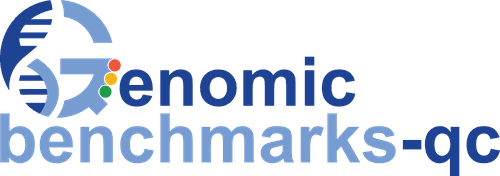

In [18]:
split_report = gbd.get_split_qc_report(
    COLLECTION, DATASET, split_a="train", split_b="test"
)
display_qc_report(split_report)